In [1]:
import tensorflow as tf

In [2]:
# Modular AI engine accepts numpy array as inputs
import numpy as np
# Utilities
from transformers import CLIPProcessor
processor = CLIPProcessor.from_pretrained("openai/clip-vit-large-patch14")


def build_model_inputs(image, captions):
    inputs = processor(text=captions, images=image, return_tensors="np", padding=True)    
    inputs['attention_mask'] = inputs['attention_mask'].astype(np.int32)
    inputs['input_ids'] = inputs['input_ids'].astype(np.int32)
    
    return inputs


def get_caption_scores(model_fn):
    inputs = build_model_inputs(image_to_caption, potential_captions)
    return model_fn(**inputs)
    

def compare_performance(model_fn_A, model_fn_B, number=100):
    from timeit import timeit, repeat

    inputs = build_model_inputs(image_to_caption, potential_captions)

    result = repeat(lambda: model_fn_A(**inputs), number=1, repeat=number)
    p50_A = np.percentile(result, 50)
    p99_A = np.percentile(result, 99)
    p100_A = np.max(result)

    result = repeat(lambda: model_fn_B(**inputs), number=1, repeat=number)
    p50_B = np.percentile(result, 50)
    p99_B = np.percentile(result, 99)
    p100_B = np.max(result)

    print(f"==== Results n_samples={number} ====")
    print(f"p50: {(p50_B / p50_A):.2f}x speed-up")
    print(f"p99: {(p99_B / p99_A):.2f}x speed-up")
    print(f"p100: {(p100_B / p100_A):.2f}x speed-up") 

# Problem setup: caption an image

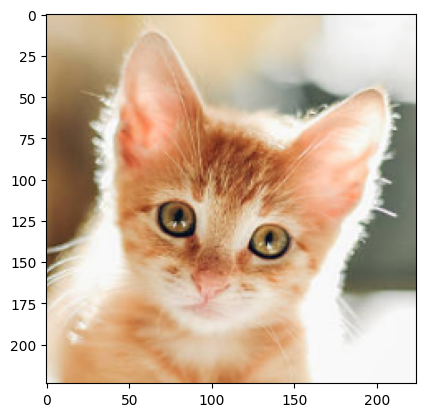

In [4]:
from PIL import Image
import matplotlib.pyplot as plt
from numpy import asarray

# The image to caption
image_to_caption = Image.open('cat.png').convert("RGB")
cat_img_input = asarray(image_to_caption)
cat_model_input = cat_img_input.T

# Set some potential captions to score
potential_captions = [
    "a cartoon drawing of a house with a red fence", 
    "a photo of a cat", 
    "a photo of a dog"
]

# Display the image and print out the captions to score
plt.imshow(cat_img_input);

# Using Tensorflow 2.13.0

In [5]:
model = tf.saved_model.load('clip-vit-tf/clip_vit_large_patch14_savedmodel')
tf_model = model.signatures['serving_default']

tf_output = get_caption_scores(tf_model)

# Print ranked (unnormalized) scores 
for label, score in sorted(zip(potential_captions, np.array(tf_output["logits_per_image"][0])), key=lambda x: -x[1]):
    print(f"Score({label}): {score:.0f}")

Score(a photo of a cat): 27
Score(a photo of a dog): 20
Score(a cartoon drawing of a house with a red fence): 6


# Using Modular Engine

In [6]:
# Import Modular AI Engine
import modular.engine as me
# Initialize a session. This can be shared between different frameworks.
session = me.InferenceSession()

# Load model from disk
modular_model = session.load('clip-vit-tf/clip_vit_large_patch14_savedmodel')

In [7]:
inputs = build_model_inputs(image_to_caption, potential_captions)
modular_outputs = modular_model.execute(**inputs)

# Print ranked (unnormalized) scores 
for label, score in sorted(zip(potential_captions, np.array(modular_outputs["logits_per_image"][0])), key=lambda x: -x[1]):
    print(f"Score({label}): {score:.0f}")

Score(a photo of a cat): 27
Score(a photo of a dog): 20
Score(a cartoon drawing of a house with a red fence): 6


# Compare inference performance between Modular and Tensorflow

In [8]:
compare_performance(modular_model.execute, tf_model, number=25)

==== Results n_samples=25 ====
p50: 2.31x speed-up
p99: 3.36x speed-up
p100: 3.66x speed-up
